# **Proper Orthogonal Decomposition (POD)**
This Lab focuses on performing POD on the parametric system we saw together in the previous Lab.

Once again, we need _a lot_ of FOM simulations this time. Let us import ``gedim``!

In [13]:
import numpy as np
import argparse
import os.path
import scipy.sparse
import vtk
from pypolydim import polydim, gedim
from pypolydim.export_vtk_utilities import ExportVTKUtilities
from pypolydim.assembler_utilities import assembler_utilities

import sys
sys.path.insert(1, './ROM_POD')
import ROM_POD.other_utilities as other_ut

In [14]:
geometry_utilities_config = gedim.GeometryUtilitiesConfig()
geometry_utilities_config.tolerance1_d = 1.0e-6
geometry_utilities_config.tolerance2_d = 1.0e-12
geometry_utilities = gedim.GeometryUtilities(geometry_utilities_config)
mesh_utilities = gedim.MeshUtilities()
vtk_utilities = ExportVTKUtilities()

## The parametric version of the heat conductivity equation

Solve the following equation on square ${\Omega} = (-1, +1) \times (-1, +1)$

$$
\begin{cases}
\nabla \cdot (k_{\mu} \nabla u) = 0 & \text{in } \Omega\\
k_{\mu} \nabla u \cdot n_1 = \mu_2 & \text{in } \Gamma_{base}\\
u = 0 & \text{in } \Gamma_{top}\\
k_{\mu} \nabla u \cdot n_2 = 0 & \text{otherwise} 
\end{cases}
$$

where $k_{\mu} = \mu_1$ if $x^2 + y^2 \leq R^2$ and $k = 1$ otherwise. 
The parametric space is $\mathcal P = [0.1, 10] \times [-1,1]$.

<img src="./ROM_POD/Images/ROM_problem1_domain.png" width=30% style="margin-left:auto; margin-right:auto">


The parameter $\boldsymbol \mu \in \mathcal P$ is physical and changes the features of the flow: 

1. $\mu_1$ the conductivity in $\Omega_1$;
2. $\mu_2$ describes the heat flux in the bottom part of the boundary.

First thing: we define two subdomains $\Omega_1$ and $\Omega_2$, such that
1. $\Omega_1$ is a disk in the origin with radius $r_0=0.5$, and
2. $\Omega_2=\Omega/\ \overline{\Omega_1}$.
3. $\Gamma_{base}$ to define where we will change the heat flux.


In [15]:
# Export folder
export_file_path = "./Export/ROM_POD"
if not os.path.exists(export_file_path):
    os.makedirs(export_file_path)

# Mesh file path
export_mesh_path = export_file_path + "/Mesh"
if not os.path.exists(export_mesh_path):
    os.makedirs(export_mesh_path)

# Solution file path
export_solution_path = export_file_path + "/Solution"
if not os.path.exists(export_solution_path):
    os.makedirs(export_solution_path)

mesh_type = polydim.pde_tools.mesh.pde_mesh_utilities.MeshGenerator_Types_2D.triangular_simple_importer
method_type = polydim.pde_tools.local_space_pcc_2_d.MethodTypes.fem_pcc
import_mesh_folder = "./ROM_POD/Mesh3"
method_order = 1

**Goal**: build the ROM space where many simulations for several parameters can be performed in a smaller amount of time. 

**Strategy**: $w(\boldsymbol  \mu)  \xrightarrow[]{\text{FOM} (\dim = \mathcal N)} w^{\mathcal N}(\boldsymbol \mu)
\xrightarrow[\lvert \lvert {w(\boldsymbol \mu) - w^\mathcal{N}(\boldsymbol  \mu)\rvert \rvert } \rightarrow 0]{\text{ROM } (\dim N)} w_N(\boldsymbol  \mu)$.

The goal can be reached by means of several techniques. 

Today we will focus on POD.

POD is an _explore_ and _compress_ algorithm based on two different stages:
1. we _explore_ the information related to the solution varying with respect to $\boldsymbol \mu$ (_snapshots_) in a finite dimensional set $\mathcal P_{train} \subset \mathcal P$.
2. We compress the redundant information and retain only the most significant "linear directions", building a linear subspace $\mathbb V_N \subset \mathbb V^{\mathcal N}$ of dimension $N \ll \mathcal N$.

Building the space and store the $\boldsymbol \mu$-independent quantities is the so called _offline phase_ (possibly costly).

Once the space is built, a fast _online phase_ occurs, where I can compute **many solutions in real-time**.

How is it possible? By means of **the affine decomposition**! Indeed we know that our system can be written as

$$
\sum_{i=1}^{q_a} \theta_i^a(\boldsymbol \mu)a_i(u,v) = \sum_{i=0}^{q_f} \theta_i^f(\boldsymbol \mu)f_i(v),
$$

i.e., algebraic-wise

$$
\sum_{i=1}^{q_a} \theta_i^a(\boldsymbol \mu)\mathsf A_i = \sum_{i=0}^{q_f} \theta_i^f(\boldsymbol \mu)\mathsf f_i,
$$
where $\mathsf A_i$ and $\mathsf f_i$ are the assembled matrices and vectors of the system.

Now, let us imagine to have already built the reduced space and have collected the basis functions $\xi_{i} \in \mathbb R^{\mathcal N}$ for $i \in \{1, \dots, N \}$ ($\mathbb V_N = \text{span}\{\xi_i\}_{i=1}^{N} $) in a basis matrix 
$$
\mathbb B = [\xi_1 \cdots \xi_N] \in \mathbb R^{\mathcal N \times N}.
$$ 

It is clear that we can recast the problem in the low-dimensional framework we built, we can pre-and-post multiply the FOM matrices for the basis matrix we have:

$$
\mathsf A_i^N = \mathbb B^T\mathsf A_i\mathbb B \quad \text{ and } \quad  \mathbb B^T\mathsf f_i.  
$$

**Here is where the offline phase ends!!**

**Question time!**: where did it start?


**Let us code the OFFLINE PHASE**

In [16]:
mesh_data = gedim.MeshMatrices()
mesh = gedim.MeshMatricesDAO(mesh_data)

polydim.pde_tools.mesh.pde_mesh_utilities.import_mesh_2_d(geometry_utilities,
                                                          mesh_type,
                                                          import_mesh_folder,
                                                          mesh)
mesh_geometric_data = polydim.pde_tools.mesh.pde_mesh_utilities.compute_mesh_2_d_geometry_data(geometry_utilities, mesh)

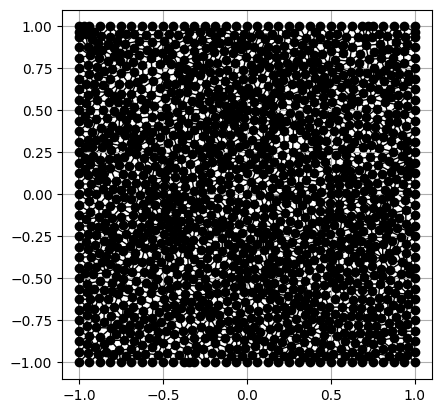

In [17]:
vtk_utilities.export_mesh(export_mesh_path, mesh)
other_ut.plot_mesh(mesh)

### FEM space (the High Fidelity approximation)

In [18]:
#### Labels \Gamma_down = 1 (neumann mu_2) , \Gamma_side = 2 (neumann 0) and \Gamma_top = 3 (dirichlet 0)
 
info_internal = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.none)
info_internal.marker = 0

info_dirichlet_up = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.strong)
info_dirichlet_up.marker = 3

info_neumann_down = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.weak)
info_neumann_down.marker = 1

info_neumann_none = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.none)
info_neumann_none.marker = 2

boundary_info = {
    0: info_internal,
    1: info_neumann_down,
    2: info_neumann_none,
    3: info_dirichlet_up
}

In [19]:
mesh_connectivity_data = polydim.pde_tools.mesh.MeshMatricesDAO_mesh_connectivity_data(mesh)

trial_reference_element_data = polydim.pde_tools.local_space_pcc_2_d.create_reference_element(method_type, method_order)
test_reference_element_data = polydim.pde_tools.local_space_pcc_2_d.create_reference_element(method_type, method_order)

dof_manager = polydim.pde_tools.do_fs.DOFsManager()

trial_mesh_dofs_info = polydim.pde_tools.local_space_pcc_2_d.set_mesh_do_fs_info(trial_reference_element_data, mesh, boundary_info)
trial_dofs_data = dof_manager.create_do_fs_2_d(trial_mesh_dofs_info, mesh_connectivity_data)
test_mesh_dofs_info = polydim.pde_tools.local_space_pcc_2_d.set_mesh_do_fs_info(trial_reference_element_data, mesh, boundary_info)
test_dofs_data = dof_manager.create_do_fs_2_d(test_mesh_dofs_info, mesh_connectivity_data)

### Assemble linear system exploting affinity
We define everything that is parameter independent, i.e.
$a_1(u,v)$, $a_2(u,v)$ and $f(v)$.
We need also the matrix related to the scalar product of the problem at hand.


In [20]:
R = 0.5

def omega_1(x, y, z):
    if (x * x + y * y) <= (R * R + 1.0e-13):
        return 1.0
    return 0.0

A_omega_1 = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_diffusion_operator(geometry_utilities,
                                                                                      mesh,
                                                                                      mesh_geometric_data,
                                                                                      trial_dofs_data,
                                                                                      test_dofs_data,
                                                                                      trial_reference_element_data,
                                                                                      test_reference_element_data,
                                                                                      omega_1)
A_1 = other_ut.make_np_sparse(A_omega_1.operator_dofs)
A_1_D = other_ut.make_np_sparse(A_omega_1.operator_strong)

def omega_2(x, y, z):
    if (x * x + y * y) <= (R * R + 1.0e-13):
        return 0.0
    return 1.0

A_omega_2 = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_diffusion_operator(geometry_utilities,
                                                                                      mesh,
                                                                                      mesh_geometric_data,
                                                                                      trial_dofs_data,
                                                                                      test_dofs_data,
                                                                                      trial_reference_element_data,
                                                                                      test_reference_element_data,
                                                                                      omega_2)
A_2 = other_ut.make_np_sparse(A_omega_2.operator_dofs)
A_2_D = other_ut.make_np_sparse(A_omega_2.operator_strong)

#### inner product  
# (||u||^2) + ||grad(u)||^2

def inner_react(x, y, z):
    return 1.0

A_l_2 = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_reaction_operator(geometry_utilities,
                                                                                      mesh,
                                                                                      mesh_geometric_data,
                                                                                      trial_dofs_data,
                                                                                      test_dofs_data,
                                                                                      trial_reference_element_data,
                                                                                      test_reference_element_data,
                                                                                      inner_react)
A_L2 = other_ut.make_np_sparse(A_l_2.operator_dofs)

inner_product = A_1 + A_2 + A_L2  ######## norm
inner_product = A_1 + A_2  ######## semi-norm (equivalent)

def weak_term_function(marker, x, y, z):
    match marker:
        case 1:
            return 1.0
        case _:
            raise ValueError("not valid marker", marker)

weak_term = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_weak_term(geometry_utilities,
                                                                             mesh,
                                                                             mesh_geometric_data,
                                                                             trial_mesh_dofs_info,
                                                                             test_dofs_data,
                                                                             trial_reference_element_data,
                                                                             test_reference_element_data,
                                                                             weak_term_function)

def strong_solution_function(marker, x, y, z):  
    return 0.0

u_D = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_strong_solution(geometry_utilities,
                                                                       mesh,
                                                                       mesh_geometric_data,
                                                                       trial_mesh_dofs_info,
                                                                       trial_dofs_data,
                                                                       trial_reference_element_data,
                                                                       strong_solution_function)

We here define the finite parametric space $\mathcal P_{train}$, with random uniform distributed realization of $\boldsymbol \mu$.
The cardinality of $\mathcal P_{train}$ is set to 100 and we call it $M$.

In [21]:
### define the training set

snapshot_num = 100 # (M)
mu1_range = [0.1, 10.]
mu2_range = [-1., 1.]
P = np.array([mu1_range, mu2_range])

training_set = np.random.uniform(low=P[:, 0], high=P[:, 1], size=(snapshot_num, P.shape[0]))


We now need to define the _snapshot matrix_. The snapshot matrix is $\mathbb U \in \mathbb R^{{M} \times {\mathcal N}}$ 

In [22]:
#### snapshot matrix creation
thetaA1 = 1.
snapshot_matrix = []

tol = 1. - 1e-7  
N_max = 10

for mu in training_set:
    thetaA2 = mu[0]
    thetaf1 = mu[1]
    
    A = thetaA1 * A_1 + thetaA2 * A_2
    f = thetaf1 * weak_term

    snapshot = scipy.sparse.linalg.spsolve(A, f)
    snapshot_matrix.append(np.copy(snapshot))

snapshot_matrix = np.array(snapshot_matrix) 

print(snapshot_matrix.shape)

(100, 1453)


**It's time for the POD**

To build the $N$-dimesional framework we need, we define the correlation snapshot matrix $\mathbf C \in \mathbb R^{M \times M}$ and we solve the eigenvalue problem
$
    \mathbf C \omega_n = \lambda_n \omega_n
$ for $ 1 \leq n \leq M,$ with $\lvert \lvert {\omega_n}\rvert \rvert_{\mathbb V} = 1$. 
Due to the definition of correlation matrix, we can order the all-positive eigenvalues as $\lambda_1 >\dots > \lambda_{M}> 0$ and retain the first $N$ eigenpairs $(\lambda_n, \omega_n)$ for $1 \leq n \leq N$. 

**Question Time**: how can I choose $M$ and $N$?

Looking at the eigenvalues! 
Indeed, defining as  $P_N: \mathbb V \rightarrow \mathbb V_N$ the projector from $\mathbb V$ onto $ {\mathbb V}_N$, the following relation holds:
\begin{equation}
    \sqrt{\frac{1}{M}
    \sum_{i = 1}^{M}  \lvert \lvert {u^{\mathcal N}(\boldsymbol{\mu}_{i}) - P_N(u^{\mathcal N}(\boldsymbol{\mu}_i))\rvert \rvert }_{2}^2} = \sqrt{
    \sum_{i = N + 1}^{M}\lambda_m.}
\end{equation}
Namely, a fast decay of the eigenvalue magnitude guaratees a good representation of the high-fidelity solution with a few basis functions.

In [23]:
### covariance matrix

C = snapshot_matrix @ inner_product @ np.transpose(snapshot_matrix) 

###### shape?? ############

#### ALTERNATIVE:  VM, L, VMt = np.linalg.svd((C))

L_e, VM_e = np.linalg.eig(C)
eigenvalues = []
eigenvectors = []


#### check


for i in range(len(L_e)):
  eig_real = L_e[i].real
  eig_complex = L_e[i].imag
  assert np.isclose(eig_complex, 0.)
  eigenvalues.append(eig_real)
  eigenvectors.append(VM_e[i].real)


total_energy = sum(eigenvalues)
retained_energy_vector = np.cumsum(eigenvalues)
relative_retained_energy = retained_energy_vector/total_energy


if all(flag==False for flag in relative_retained_energy>= tol):
  N = N_max
else:
  N = np.argmax(relative_retained_energy >= tol) + 1

print("The reduced dimension is", N)

The reduced dimension is 3


We still need to create the basis matrix $\mathbb B$. There are many ways to build the bases.
We propose the following one to guarantee more stability:
$$    
\chi_n =  \sum_{m = 1}^{M} (\omega_n)_m u^{\mathcal N}(\boldsymbol{\mu}_m),  \quad \quad 1 \leq n \leq N,
$$

and $\displaystyle \xi_n = \frac{\chi_n}{\lvert \lvert \chi_n \rvert \rvert }_{\mathbb V}$.


$P_N: \mathbb V \rightarrow \mathbb V_N$ is defined as

$$
P_N(u^{\mathcal N}(\boldsymbol \mu)) = \sum_{i=1}^N (u^{\mathcal N}(\boldsymbol \mu), \xi_n)\xi_n,
$$

or algebraically $\mathbb P_N = \mathbb B \mathbb B^T$.

In [24]:
# Create the basis function matrix
basis_functions = []
for n in range(N):
  eigenvector =  eigenvectors[n]
  
  # basis = (1/np.sqrt(snapshot_num))*np.transpose(snapshot_matrix)@eigenvector  (This is the one of the book!!)
  
  basis = np.transpose(snapshot_matrix)@eigenvector
  norm = np.sqrt(np.transpose(basis) @ inner_product @ basis) 
  
  basis /= norm
  basis_functions.append(np.copy(basis))

basis_functions = np.transpose(np.array(basis_functions))

The offline stage ends once the **reduced operators** are built, i.e. $\mathsf A_1^{N}$, $\mathsf A_2^{N}$ and $\mathsf f_1^{N}$ thanks to the basis matrix projections.

In [25]:
########## ASSEMBLE THE LINEAR SYSTEM ##### STILL OFFLINE
reduced_A1 = np.transpose(basis_functions) @ A_1 @ basis_functions
reduced_A2 = np.transpose(basis_functions) @ A_2 @ basis_functions
reduced_f =  np.transpose(basis_functions) @ weak_term

### shape? ##### 

### **Online Phase: a new parameter!** ###
In the _online phase_ we can use all the pre-assembled quantities to generate a new solution for a new parameter. 



In [26]:
thetaA2 = 2.
thetaf1 = 0.8

In [27]:
reduced_rhs = thetaA1*reduced_A1 + thetaA2*reduced_A2
reduced_lhs = thetaf1*reduced_f

In [28]:
##### solve ######### 

reduced_solution = np.linalg.solve(reduced_rhs, reduced_lhs)
proj_reduced_solution = basis_functions @ reduced_solution

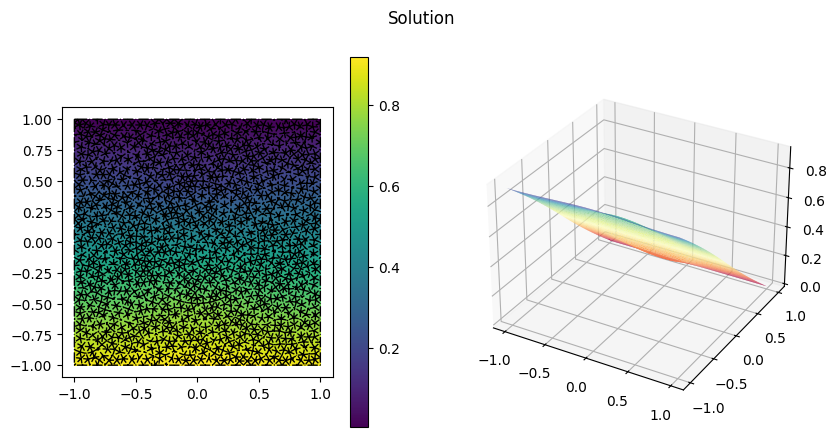

In [29]:
proj_reduced_on_cell0Ds = polydim.pde_tools.assembler_utilities.pcc_2_d.extract_solution_on_cell0_ds(mesh,
                                                                                          trial_dofs_data,
                                                                                          proj_reduced_solution,
                                                                                          u_D)

vtk_utilities.export_solution_2(export_solution_path + '/u_reduced',
                                mesh, 
                                proj_reduced_on_cell0Ds.numeric_solution)
other_ut.plot_solution(mesh, proj_reduced_on_cell0Ds.numeric_solution) 

In [30]:
A = thetaA1*A_1 + thetaA2*A_2
f = thetaf1*weak_term

full_solution = scipy.sparse.linalg.spsolve(A, f)

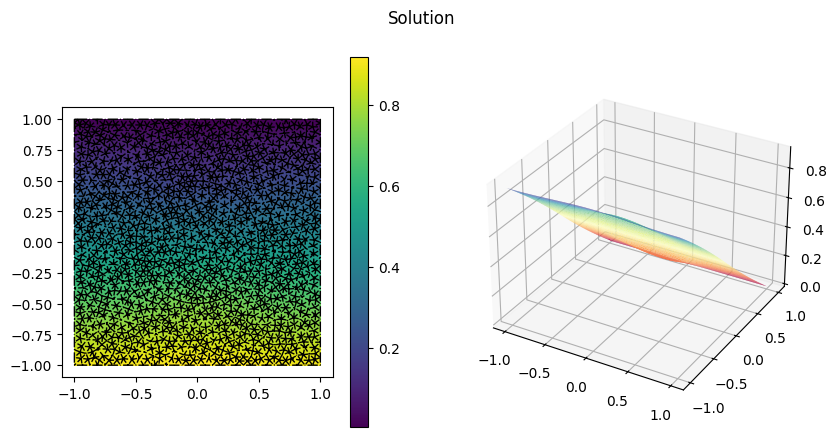

In [31]:
proj_full_on_cell0Ds = polydim.pde_tools.assembler_utilities.pcc_2_d.extract_solution_on_cell0_ds(mesh,
                                                                                          trial_dofs_data,
                                                                                          full_solution,
                                                                                          u_D)

vtk_utilities.export_solution_2(export_solution_path + '/u_full',
                                mesh, 
                                proj_full_on_cell0Ds.numeric_solution)
other_ut.plot_solution(mesh, proj_full_on_cell0Ds.numeric_solution) 

We can now compute an error analysis over the parametric space, together with a _speed-up_ anaslysis.

The speed-up is an index that evaluated how many ROM solution I can obtain in the time of a FOM simulation.

In [32]:
### compute error
import time

abs_err = []
rel_err = []
testing_set = np.random.uniform(low=P[:, 0], high=P[:, 1], size=(100, P.shape[0]))
speed_up = []

print("Computing error and speedup analysis")

for mu in testing_set:
    
    thetaA2 = mu[0]
    thetaf1 = mu[1]
        
    ##### full #####
    A = thetaA1*A_1 + thetaA2*A_2
    f = thetaf1*weak_term
  
    start_fom = time.time()
    full_solution = scipy.sparse.linalg.spsolve(A, f)
    time_fom = time.time() - start_fom
    
    #### reduced #####
    
    reduced_rhs = thetaA1*reduced_A1 + thetaA2*reduced_A2
    reduced_lhs = thetaf1*reduced_f
    
    start_rom = time.time()
    reduced_solution = np.linalg.solve(reduced_rhs, reduced_lhs)
    time_rom = time.time() - start_rom
    
    speed_up.append(time_fom/time_rom)
    
    proj_reduced_solution = basis_functions@reduced_solution
    
    ### computing error
    
    error_function = full_solution - proj_reduced_solution
    error_norm_squared_component = np.transpose(error_function) @ inner_product @ error_function
    absolute_error = np.sqrt(abs(error_norm_squared_component))
    abs_err.append(absolute_error)
    
    full_solution_norm_squared_component = np.transpose(full_solution) @  inner_product @ full_solution
    relative_error = absolute_error/np.sqrt(abs(full_solution_norm_squared_component))
    rel_err.append(relative_error)

print("average relative error = ", np.mean(rel_err) )
print("average absolute error = ", np.mean(abs_err) )
print("average speed_up = ", np.mean(speed_up) )

Computing error and speedup analysis
average relative error =  4.9169188673372644e-05
average absolute error =  1.8230097806665063e-05
average speed_up =  119.44046309918744


**Exercise**: solve the same problem but with $u = 3$ on $\Gamma_{top}$.